# 05 — k-fqinjët më të afërt (k-NN)

        **Pyetja udhëheqëse:** Si mund të klasifikojmë një gjendje fizike vetëm nga afërsia me shembuj të njohur?

        Ky notebook është ndërtuar si një mësim i plotë kompjuterik. Rruga kryesore ndjek:
        **problem konkret → model matematikor → zbatim nga parimet e para → bibliotekë profesionale → krahasim → interpretim**.

        ## Objektivat
        - Të kuptohet metrika e distancës.
- Të implementohet k-NN nga zero.
- Të analizohet roli i k dhe standardizimit.
- Të ilustrohet mallkimi i dimensionalitetit.

        > **Rruga bazë për orën mësimore (45–60 min)** shënohet me seksionet **CORE**.  
        > Seksionet **EXTENDED** dhe **PLAYGROUND** janë për thellim dhe punë të pavarur.

## Pse kjo temë është e nevojshme?

k-NN është një algoritëm i thjeshtë në formë, por shumë i pasur konceptualisht: ai na detyron të pyesim çfarë do të thotë “afër” në një hapësirë veçorish dhe si ndikojnë njësitë fizike, shkallëzimi dhe dimensionaliteti te kjo ide.

Ky notebook përdoret për të bërë të dukshme lidhjen ndërmjet gjeometrisë së të dhënave dhe performancës së algoritmit. Ndryshe nga modelet parametrike, pjesa më e madhe e “punës” së k-NN ndodh në momentin e parashikimit.

### Si duhet lexuar ky notebook

Për çdo bllok kodi do të shpjegojmë **pse** kryhet ai hap, çfarë pyetjeje i përgjigjet dhe çfarë duhet të kontrollojmë në dalje. Kodi nuk trajtohet si recetë: çdo grafik dhe çdo metrikë duhet të rikthehet te hipoteza matematikore dhe te interpretimi fizik. Kur një rezultat nuk sillet siç presim, pyetja e parë nuk është “si ta rrisim score-in?”, por “cilën hipotezë të modelit ose të të dhënave po shkelim?”.

### Para se të ekzekutojmë: Mjedisi llogaritës dhe riprodhueshmëria

Ngarkojmë bibliotekat që do të përdoren dhe fiksojmë `RANDOM_STATE = 42`. Ky seed nuk e bën problemin determinist në kuptimin fizik; ai thjesht na lejon të përsërisim të njëjtin eksperiment llogaritës dhe të diskutojmë metodën pa u hutuar nga ndryshime të rastësishme të mostrës.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

In [1]:
# Qëllimi i këtij blloku: Mjedisi llogaritës dhe riprodhueshmëria.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import numpy as np
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import pandas as pd
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import matplotlib.pyplot as plt
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from pathlib import Path
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import time

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

print("05 — k-fqinjët më të afërt (k-NN)")
print("Seed:", RANDOM_STATE)

05 — k-fqinjët më të afërt (k-NN)
Seed: 42


**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 1. Regjime dinamike si pika në hapësirën e veçorive — CORE

### Para se të ekzekutojmë: Të dhënat si gjeometri

Krijojmë dy regjime dinamike dhe i paraqesim në një hapësirë dy-dimensionale veçorish. k-NN nuk ka një ekuacion të parametrizuar për kufirin; klasifikimi del nga gjeometria lokale e këtyre pikave.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

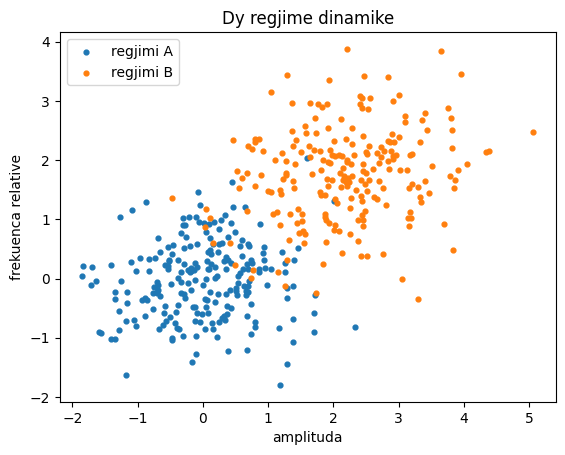

In [2]:
# Qëllimi i këtij blloku: Të dhënat si gjeometri.
n=220
# Gjenerojmë të dhëna të kontrolluara që na lejojnë të dimë strukturën që duhet të zbulojë modeli.
reg0=rng.normal([0,0],[0.8,0.7],size=(n,2))
# Gjenerojmë të dhëna të kontrolluara që na lejojnë të dimë strukturën që duhet të zbulojë modeli.
reg1=rng.normal([2.2,1.8],[0.9,0.8],size=(n,2))
X=np.vstack([reg0,reg1]); y=np.r_[np.zeros(n),np.ones(n)]
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
ax.scatter(reg0[:,0],reg0[:,1],s=12,label="regjimi A")
ax.scatter(reg1[:,0],reg1[:,1],s=12,label="regjimi B")
ax.legend(); ax.set_xlabel("amplituda"); ax.set_ylabel("frekuenca relative")
ax.set_title("Dy regjime dinamike")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

k-NN nuk ndërton një funksion parametrik. Për një pikë të re $x$, llogarit distancat ndaj të gjitha
mostrave të trajnimit dhe përdor votën e $k$ fqinjëve më të afërt.

# 2. Distanca dhe zbatimi manual — CORE

### Para se të ekzekutojmë: Implementimi i mekanizmit bazë

Funksioni manual llogarit distancat, rendit fqinjët dhe bën votimin. Çdo linjë korrespondon me një hap të përkufizimit matematikor të k-NN. Kjo e bën të dukshme pse algoritmi është i lirë në trajnim por relativisht i kushtueshëm në parashikim.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

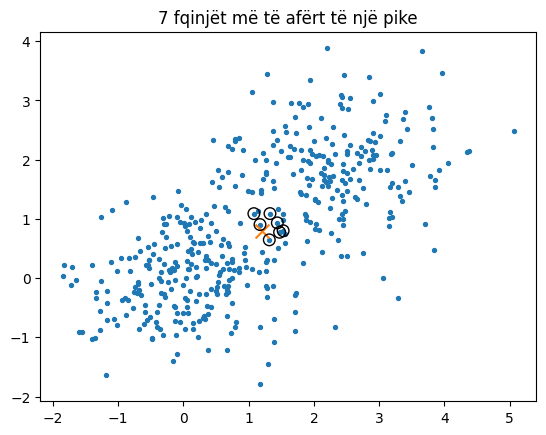

In [3]:
# Qëllimi i këtij blloku: Implementimi i mekanizmit bazë.
def knn_predict(X_train,y_train,X_query,k=5):
    out=[]
    for q in np.asarray(X_query):
        d=np.linalg.norm(X_train-q,axis=1)
        # Renditja përdoret për të identifikuar fqinjët ose komponentët sipas kriterit përkatës.
        idx=np.argsort(d)[:k]
        labels,counts=np.unique(y_train[idx],return_counts=True)
        out.append(labels[np.argmax(counts)])
    return np.asarray(out)

q=np.array([[1.2,0.8]])
d=np.linalg.norm(X-q,axis=1)
# Renditja përdoret për të identifikuar fqinjët ose komponentët sipas kriterit përkatës.
idx=np.argsort(d)[:7]
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
ax.scatter(X[:,0],X[:,1],s=8)
ax.scatter(q[:,0],q[:,1],s=100,marker="x")
ax.scatter(X[idx,0],X[idx,1],s=70,facecolors="none",edgecolors="black")
ax.set_title("7 fqinjët më të afërt të një pike")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

### I njëjti algoritëm si modul i ripërdorshëm

### Para se të ekzekutojmë: Moduli i ripërdorshëm

Pasi kemi parë mekanizmin, e përdorim versionin kanonik nga `src/`. Krahasimi ndihmon të kuptohet se abstraksioni software-ik nuk duhet të fshehë matematikën që kemi sapo implementuar.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

In [4]:
# Qëllimi i këtij blloku: Moduli i ripërdorshëm.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import sys
# Kërkojmë automatikisht rrënjën e repository-t, në mënyrë që notebook-u të funksionojë nga dosje të ndryshme.
ROOT = Path.cwd()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "src").is_dir():
        sys.path.insert(0, str(candidate))
        break
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from src.neighbors.knn import KNNClassifier
# Përshtatim parametrat e modelit mbi bashkësinë e trajnimit.
knn_src = KNNClassifier(k=7).fit(X, y)
# Llogarisim parashikimet mbi të dhëna që nuk përdoren për të ndryshuar parametrat e modelit.
print("Parashikimi src për q:", knn_src.predict(q))

Parashikimi src për q: [1.]


**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 3. Kufijtë e vendimit dhe roli i k — CORE

### Para se të ekzekutojmë: k si parametër i kompleksitetit

Kufijtë për disa vlera të k tregojnë kompromisin bias–variance në formë gjeometrike. $k=1$ ndjek hollësitë lokale; k i madh mesatarizon mbi rajone më të gjera.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

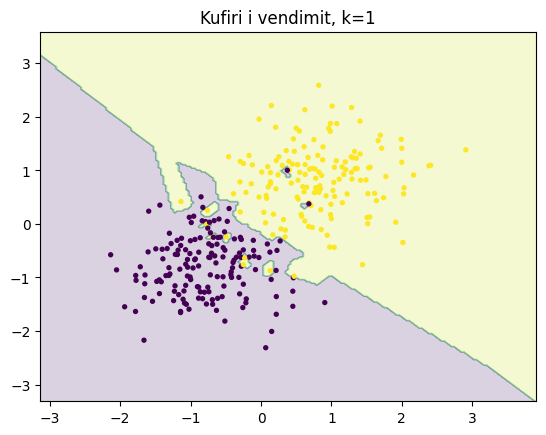

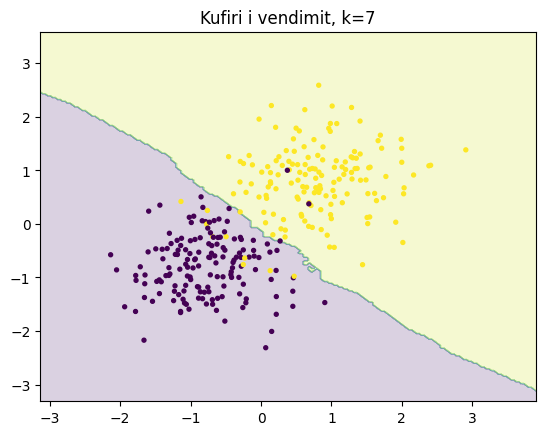

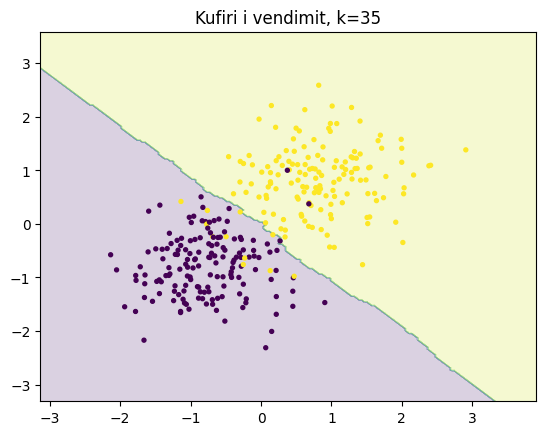

In [5]:
# Qëllimi i këtij blloku: k si parametër i kompleksitetit.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.model_selection import train_test_split
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.preprocessing import StandardScaler
# Ndajmë të dhënat në mënyrë të riprodhueshme; test-i nuk përdoret për trajnim.
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=0.3,stratify=y,random_state=RANDOM_STATE)
# Përshtatim standardizimin vetëm mbi të dhënat e trajnimit për të shmangur leakage.
sc=StandardScaler().fit(Xtr)
Xs,Xts=sc.transform(Xtr),sc.transform(Xte)

def plot_boundary(k):
    xx,yy=np.meshgrid(np.linspace(Xs[:,0].min()-1,Xs[:,0].max()+1,200),
                      np.linspace(Xs[:,1].min()-1,Xs[:,1].max()+1,200))
    pred=knn_predict(Xs,ytr,np.c_[xx.ravel(),yy.ravel()],k).reshape(xx.shape)
    # Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
    fig,ax=plt.subplots()
    ax.contourf(xx,yy,pred,alpha=0.2)
    ax.scatter(Xs[:,0],Xs[:,1],c=ytr,s=8)
    ax.set_title(f"Kufiri i vendimit, k={k}")
    plt.show()

for k in [1,7,35]:
    plot_boundary(k)

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

**Interpretim.** k i vogël krijon kufij të ndërlikuar dhe mund të mbipërshtatet; k shumë i madh i zbut kufijtë dhe mund të humbasë strukturë lokale.

Në një analizë reale ky interpretim duhet të shoqërohet me kontroll të njësive, madhësive karakteristike dhe hipotezave që lejojnë kalimin nga një tregues numerik te një përfundim fizik.

# 4. Krahasim me scikit-learn — CORE

### Para se të ekzekutojmë: Krahasimi sasior

Matim accuracy për disa k. Ky hap duhet lexuar së bashku me grafikët e kufirit: dy modele mund të kenë score të ngjashëm por sjellje lokale shumë të ndryshme.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

In [6]:
# Qëllimi i këtij blloku: Krahasimi sasior.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.neighbors import KNeighborsClassifier
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.metrics import accuracy_score
for k in [1,3,5,9,15,31]:
    # Përshtatim parametrat e modelit mbi bashkësinë e trajnimit.
    m=KNeighborsClassifier(n_neighbors=k).fit(Xs,ytr)
    # Llogarisim parashikimet mbi të dhëna që nuk përdoren për të ndryshuar parametrat e modelit.
    print(k, accuracy_score(yte,m.predict(Xts)))

1 0.9318181818181818
3 0.946969696969697
5 0.9393939393939394
9 0.946969696969697
15 0.9545454545454546
31 0.9621212121212122


**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 5. Pse standardizimi është i domosdoshëm — CORE

### Para se të ekzekutojmë: Krahasimi sasior

Matim accuracy për disa k. Ky hap duhet lexuar së bashku me grafikët e kufirit: dy modele mund të kenë score të ngjashëm por sjellje lokale shumë të ndryshme.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

In [7]:
# Qëllimi i këtij blloku: Krahasimi sasior.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.pipeline import make_pipeline
X_bad=X.copy()
X_bad[:,1]*=1000  # njësi arbitrare shumë më të mëdha
# Ndajmë të dhënat në mënyrë të riprodhueshme; test-i nuk përdoret për trajnim.
Xtr,Xte,ytr,yte=train_test_split(X_bad,y,test_size=0.3,stratify=y,random_state=RANDOM_STATE)
# Përshtatim parametrat e modelit mbi bashkësinë e trajnimit.
raw=KNeighborsClassifier(7).fit(Xtr,ytr).score(Xte,yte)
# Përshtatim standardizimin vetëm mbi të dhënat e trajnimit për të shmangur leakage.
pipe=make_pipeline(StandardScaler(),KNeighborsClassifier(7)).fit(Xtr,ytr).score(Xte,yte)
raw,pipe

(0.8484848484848485, 0.946969696969697)

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

---
## Deri këtu: materiali bazë për orën mësimore

Në një seancë rreth 60 minuta, zakonisht ndalemi këtu. Seksionet që vijojnë janë për thellim,
ushtrime të pavarura dhe eksperimentim.

# 6. Mallkimi i dimensionalitetit — EXTENDED

### Para se të ekzekutojmë: Mallkimi i dimensionalitetit

Në dimension të lartë, distanca më e afërt dhe më e largët bëhen relativisht më të ngjashme. Kur kjo ndodh, nocioni i “fqinjit” humbet fuqi diskriminuese dhe k-NN bëhet më problematik.

**Çfarë duhet të vëzhgojmë?** Pas ekzekutimit, kontrolloni jo vetëm vlerën numerike, por edhe nëse drejtimi i ndryshimit, shkalla e madhësive dhe forma e grafikut janë në përputhje me pritshmërinë teorike. Kjo e kthen qelizën nga një komandë programimi në një hap të arsyetimit shkencor.

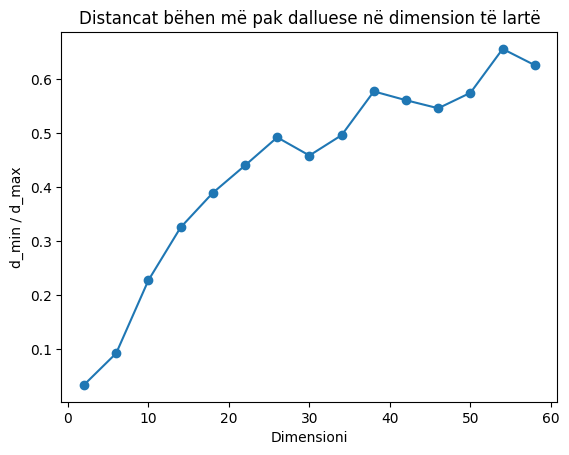

In [8]:
# Qëllimi i këtij blloku: Mallkimi i dimensionalitetit.
dims=np.arange(2,61,4)
ratio=[]
for d in dims:
    # Gjenerojmë të dhëna të kontrolluara që na lejojnë të dimë strukturën që duhet të zbulojë modeli.
    pts=rng.normal(size=(700,d))
    # Gjenerojmë të dhëna të kontrolluara që na lejojnë të dimë strukturën që duhet të zbulojë modeli.
    q=rng.normal(size=(1,d))
    ds=np.linalg.norm(pts-q,axis=1)
    ratio.append(ds.min()/ds.max())
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig,ax=plt.subplots()
ax.plot(dims,ratio,marker="o")
ax.set_xlabel("Dimensioni"); ax.set_ylabel("d_min / d_max")
ax.set_title("Distancat bëhen më pak dalluese në dimension të lartë")
plt.show()

**Pyetje për interpretim.** Çfarë përfundimi lejon ky rezultat dhe çfarë **nuk** lejon të përfundojmë? Nëse do të ndryshonim zhurmën, madhësinë e kampionit ose ndarjen e të dhënave, cilën pjesë të rezultatit prisni të ishte më e ndjeshme?

# 7. Aplikim jo-fizik: njohje shkrimi — EXTENDED

Në klasifikimin e shifrave të shkruara, çdo imazh mund të shihet si një pikë në një hapësirë me qindra dimensione; kjo tregon pse reduktimi dimensional ose metrika më të përshtatshme bëhen të rëndësishme.

# Ushtrime — PLAYGROUND

        ## A. Ushtrime të shkurtra
        1. Krahasoni distancën Euklidiane me Manhattan.
2. Gjeni k optimal me validim të kryqëzuar.
3. Analizoni klasifikimin për një pikë pranë kufirit.
4. Shpjegoni pse k-NN ka kosto të lartë në fazën e parashikimit.

        ## B. Ushtrim i plotë
        Gjeneroni tre regjime dinamike me mbivendosje të ndryshme dhe ndërtoni një hartë të accuracy ndaj k.

        ## C. Playground
        Ndryshoni k, dimensionin, shkallën e veçorive dhe nivelin e zhurmës.

In [9]:
# TODO / PLAYGROUND
# Ndryshoni parametrat, shtoni grafikë ose krahasoni modele të tjera.

## Përmbledhje konceptuale e kapitullit

Notebook-u **k-fqinjët më të afërt** duhet të lihet me një ide të qartë: algoritmi është vetëm një hallkë e arsyetimit. Para tij kemi zgjedhjen e përfaqësimit dhe hipotezat mbi të dhënat; pas tij kemi validimin, diagnostikën dhe interpretimin. Nëse një student mund të ekzekutojë të gjitha qelizat por nuk mund të shpjegojë pse secila prej tyre është e nevojshme, atëherë puna llogaritëse nuk është përfunduar ende.

Për studim të mëtejshëm, rikthehuni te shënimet e leksionit për derivimet e plota dhe përdoreni këtë notebook si laborator ku këto ide testohen numerikisht.

### Zgjidhje orientuese për instruktorin
- Manhattan përdor $\sum_j|x_j-x'_j|$ dhe mund të sillet ndryshe nga Euklidiana në dimension të lartë.
- $k$ zgjidhet me validim; $k=1$ ka variancë të madhe, $k$ shumë i madh ka bias të madh.
- Pa standardizim, veçoria me shkallën numerike më të madhe dominon distancën.